# Hello · SEM — forward and backward

The smallest `sweep.sem` story: the two-layer model of *Hello · SWEEP*, solved
with the spectral-element method instead of finite differences. `PropSEM` takes
`PropTorch`'s call -- a wavelet, integer grid sources and receivers,
`models=[vp]` on the grid -- so only the construction line is new.

1. **Forward** — one shot through the truth model, and its gather
2. **Backward** — one `.backward()` from a homogeneous model; ∂loss / ∂vp comes back on the grid
3. **Memory** — the same gradient with `memory=BoundarySaving()`, which keeps the absorbing band instead of the whole forward history

No external data. On CUDA it runs `impl='c'`, on CPU `impl='eager'`.

## 1. Parameters

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.propagator import BoundarySaving
from sweep.sem import PropSEM
from sweep.sem.equations import AcousticPotentialSEM2D
from sweep.sem.prop_c import sem_c_available
from sweep.signal import ricker

shape   = (97, 129)   # (nz, nx): every n - 1 must divide by n_order
dh      = 10.0
n_order = 4           # GLL degree per element, so the elements are 40 m
dt      = 1.0e-3      # set by the GLL spacing (0.172 x 40 m = 6.9 m), not by dh
nt      = 1000
freq    = 10.0
delay   = 0.12

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
impl = 'c' if device.type == 'cuda' and sem_c_available() else 'eager'
print('device:', device, '  impl:', impl)

device: cuda   impl: c


## 2. Truth and initial models

As in *Hello · SWEEP*: two layers in the truth, and a uniform 1500 m/s initial
model, so the gradient has one interface to find.

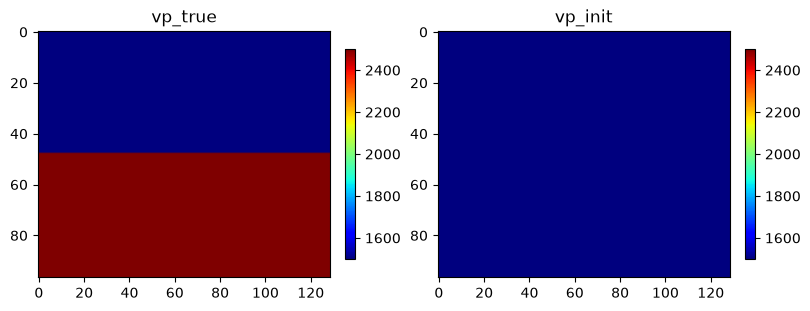

In [2]:
vp_true = np.full(shape, 1500.0, dtype=np.float32)
vp_true[shape[0] // 2:, :] = 2500.0
vp_init = np.full(shape, 1500.0, dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
for ax, m, name in zip(axes, [vp_true, vp_init], ['vp_true', 'vp_init']):
    im = ax.imshow(m, cmap='jet', aspect='auto', vmin=1500, vmax=2500)
    ax.set_title(name)
    fig.colorbar(im, ax=ax, shrink=0.85)
plt.show()

## 3. Solver, source, receivers

`PropSEM` builds the GLL mesh and the C-PML from `shape`, `dh` and `n_order`.
The `abcn`-cell absorbing layer -- whole elements, so a multiple of `n_order` --
is added outside `shape`, as the FD `abcn` is, so `shape` is the model and the
sources and receivers are its integer grid indices `[ix, iz]`. With no
`free_surface` (the default) it absorbs on all four sides, like *Hello · SWEEP*.

In [3]:
solver = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt,
                 n_order=n_order, abcn=8 * n_order, f_dominant=freq,
                 device=device.type, impl=impl)
print('mesh:', solver.mesh.n_elements, 'elements,', solver.mesh.n_global,
      'GLL nodes (the grid has', shape[0] * shape[1], 'points)')

t = np.arange(nt, dtype=np.float32) * dt
wavelet = ricker(t - delay, f=freq).astype(np.float32)
sources = np.array([[shape[1] // 2, 2]], dtype=np.int64)
rec_x = np.linspace(0, shape[1] - 1, 64).astype(np.int64)
receivers = np.stack([rec_x, np.full_like(rec_x, 4)], axis=1)[None]

mesh: 1920 elements, 31073 GLL nodes (the grid has 12513 points)


## 4. Forward — observed shot gather

One shot, one model, no autograd. The record has the FD layout,
`(shots, nt, receivers, components)`.

record: (1, 1000, 64, 1)


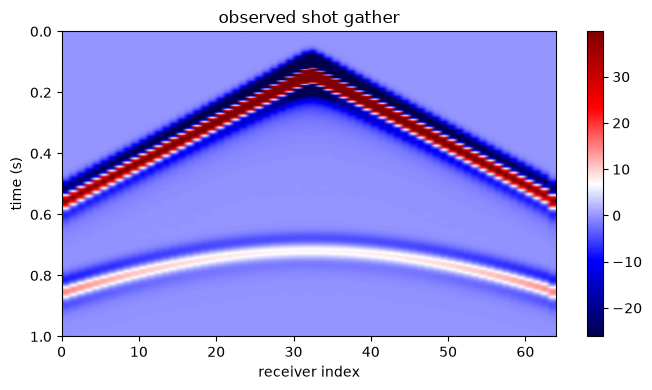

In [4]:
with torch.no_grad():
    obs = solver(wavelet, sources, receivers,
                 models=[torch.tensor(vp_true, device=device)])
print('record:', tuple(obs.shape))

gather = obs[0, :, :, 0].cpu().numpy()
vmin, vmax = np.percentile(gather, [2, 98])
plt.figure(figsize=(7, 4))
plt.imshow(gather, cmap='seismic', vmin=vmin, vmax=vmax, aspect='auto',
           extent=[0, receivers.shape[1], nt * dt, 0])
plt.xlabel('receiver index'); plt.ylabel('time (s)')
plt.title('observed shot gather')
plt.colorbar(); plt.tight_layout(); plt.show()

## 5. Backward — one velocity gradient

The model is a leaf tensor on the grid. `PropSEM` interpolates it onto the GLL
nodes inside the call, so `.backward()` puts ∂loss / ∂vp back on the grid. On
`impl='c'` the backward is the adjoint-state CUDA path; on `impl='eager'` it is
autograd through the time loop. Both keep the whole forward history by default.
On the grid the gradient keeps a faint imprint of the 40 m elements: vp reaches
each element's unevenly spaced GLL nodes by interpolation, and the gradient
comes back through the transpose of that interpolation. At the model edge it
stops, as FD's does: the absorbing layer reads the edge values of vp, but it
is not part of the model.

loss: 105509.640625
grad shape: (97, 129)  min/max: -4.169501304626465 6.031015872955322


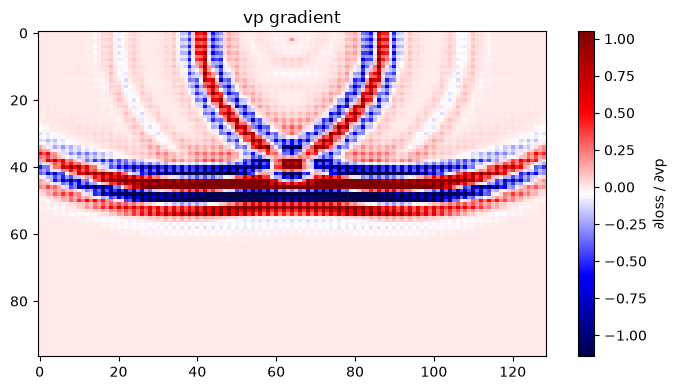

In [5]:
vp_t = torch.tensor(vp_init, device=device, requires_grad=True)
pred = solver(wavelet, sources, receivers, models=[vp_t])
loss = 0.5 * (pred - obs).pow(2).sum()
loss.backward()
grad_full = vp_t.grad.detach().clone()
print('loss:', float(loss.detach()))
print('grad shape:', tuple(grad_full.shape), ' min/max:',
      float(grad_full.min()), float(grad_full.max()))

g = grad_full.cpu().numpy()
vmin, vmax = np.percentile(g, [2, 98])
plt.figure(figsize=(7, 4))
plt.imshow(g, cmap='seismic', vmin=vmin, vmax=vmax, aspect='auto')
plt.title('vp gradient')
plt.colorbar(label='∂loss / ∂vp'); plt.tight_layout(); plt.show()

## 6. The same gradient with `memory=BoundarySaving()`

As on `PropTorch`, the memory strategy is the solver's: a second one, built with
`memory=BoundarySaving()`, keeps only the C-PML band of each time step and rebuilds
the interior wavefield backwards in time during the backward: memory stays flat
in `nt`, for one extra forward step per backward step. The two gradients are
close but not bit for bit the same -- and neither are two runs of the same
`impl='c'` backward, which accumulates with atomics.

In [6]:
solver_bs = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt,
                    n_order=n_order, abcn=8 * n_order, f_dominant=freq,
                    memory=BoundarySaving(), device=device.type, impl=impl)
vp_t = torch.tensor(vp_init, device=device, requires_grad=True)
pred = solver_bs(wavelet, sources, receivers, models=[vp_t])
(0.5 * (pred - obs).pow(2).sum()).backward()
grad_bs = vp_t.grad.detach()
rel = float((grad_bs - grad_full).norm() / grad_full.norm())
print(f'boundary saving vs full history: relative difference {rel:.1e}')

boundary saving vs full history: relative difference 5.9e-05


## Notes

* **Elastic and 3-D** follow the same pattern: `models=[vp, vs, rho]` for the
  elastic equations, `source_type=['sxx', 'szz']` for an explosion or `['vz']`
  for a vertical force (the `PropTorch` names), `receiver_type=['vx', 'vz']`
  for particle velocity, and a 3-D `shape`. The
  [SEM user guide](../../user-guide/sem/) lists the equations and the options.
* **Snapshots**: `return_wavefield=True` (eager) returns the record and the
  wavefield on the grid of the model and its absorbing layer, as `PropTorch`
  does.
* **The time step** comes from the closest pair of GLL points, about
  `0.172 x n_order x dh` at order 4, not from `dh`: an FD-sized step diverges.

---

<p><strong>Download this notebook</strong> &mdash; <a href="43_sem_forward_backward.ipynb" download><code>43_sem_forward_backward.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/43_sem_forward_backward.ipynb">view on GitHub</a></p>